# 04 - Feature Engineering

Builds the model table from `cleaned_dataset.csv`.

Rules I follow so nothing from the future gets in:
- A row at week w only uses weather, price and soil information available by week w.
- History features (last seasons' yield) only use earlier seasons.
- "Normal rainfall" is calculated from years up to 2021 only.

Target: instead of predicting yield directly I predict `yield / baseline`, where baseline is the taluka-crop average of the last 3 seasons. This keeps crops with very different yield levels on the same scale, and the model only has to learn the deviation from normal. The prediction is multiplied back by the baseline to get q/ha.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json

df = pd.read_csv('../dataset/cleaned_dataset.csv')
key = ['taluka', 'crop', 'season_year']
df = df.sort_values(key + ['season_week']).reset_index(drop=True)

# harvest week of the season for each crop (crop calendar)
HARVEST = {'soybean': 18, 'cotton': 30, 'tur': 28, 'wheat': 17, 'gram': 15}
df['harvest_wk'] = df.crop.map(HARVEST)
df['weeks_to_harvest'] = df.harvest_wk - df.season_week
print(df.shape)

(347760, 25)


## Weather features (rolling, cumulative and ratio)

In [2]:
gkey = [df[c] for c in key]

def trailing_sum(col, k):
    # sum of the last k weeks inside the same season
    cs = df.groupby(key)[col].cumsum()
    return cs - cs.groupby(gkey).shift(k).fillna(0)

df['rain_roll4'] = trailing_sum('rain_mm', 4)
df['rain_roll8'] = trailing_sum('rain_mm', 8)
df['tmax_roll4'] = trailing_sum('tmax_c', 4) / np.minimum(df.season_week, 4)
df['cum_rain'] = df.groupby(key).rain_mm.cumsum()
df['rain_missing_share'] = df.groupby(key).rain_was_missing.cumsum() / df.season_week

# rain so far compared with normal for this district, crop and week of season (normal = training years only)
normal = df[df.season_year <= 2021].groupby(['district', 'crop', 'season_week']).cum_rain.mean().rename('cum_rain_normal')
df = df.join(normal, on=['district', 'crop', 'season_week'])
df['cum_rain_ratio'] = df.cum_rain / (df.cum_rain_normal + 1)

# longest dry spell so far (weeks in a row with less than 8 mm)
dry = (df.rain_mm < 8).astype(int).values.reshape(-1, 46)      # rows are sorted so each season is 46 consecutive rows
run = np.zeros_like(dry)
longest = np.zeros_like(dry)
for j in range(46):
    run[:, j] = (run[:, j - 1] + 1) * dry[:, j] if j > 0 else dry[:, 0]
    longest[:, j] = np.maximum(longest[:, j - 1], run[:, j]) if j > 0 else run[:, 0]
df['dry_run_max'] = longest.ravel()

# weeks with max temperature above 36C after week 8 (heat stress)
hot = ((df.tmax_c > 36) & (df.season_week >= 8)).astype(int)
df['cum_heat'] = hot.groupby(gkey).cumsum()

# rain in the 16 weeks before sowing (soil moisture for the rabi crops)
piv = df.drop_duplicates(['taluka', 'abs_week']).pivot(index='abs_week', columns='taluka', values='rain_mm')
piv = piv.reindex(range(piv.index.min(), piv.index.max() + 1))
roll16 = piv.rolling(16, min_periods=16).sum().stack()
idx = pd.MultiIndex.from_arrays([df.abs_week - df.season_week, df.taluka])
df['rain_before_sowing'] = roll16.reindex(idx).values
print(df[['rain_roll4', 'cum_rain_ratio', 'dry_run_max', 'cum_heat', 'rain_before_sowing']].describe().T.round(2))

                       count    mean     std  ...     50%     75%      max
rain_roll4          347760.0   69.66  109.24  ...   25.40   81.59  1547.90
cum_rain_ratio      347760.0    0.97    0.51  ...    0.91    1.21    16.15
dry_run_max         347760.0    6.68    4.66  ...    6.00   10.00    35.00
cum_heat            347760.0    3.49    5.79  ...    0.00    5.00    25.00
rain_before_sowing  336168.0  311.47  309.30  ...  157.50  498.09  1922.84

[5 rows x 8 columns]


## Price, soil and ratio features

In [3]:
df['price_mom'] = df.price_q / df.groupby(key).price_q.shift(4) - 1                    # 4-week price change
df['price_yoy'] = df.price_q / df.groupby(['taluka', 'crop']).price_q.shift(46) - 1   # same week last season
# (I do not use the raw INR price: it drifts up with inflation and would just act as a year counter)

df['n_p_ratio'] = df.soil_N / df.soil_P

## History features (lags and rolling stats from earlier seasons)

Also the high-cardinality part. There are 84 talukas and 18 mandis. One-hot encoding 84 columns would be sparse and noisy, so:
- taluka and mandi are not used as raw categories
- the taluka's own past yields (lags) already describe it
- I add one smoothed taluka effect: its average yield relative to the district-crop average in earlier years, pulled towards 1.0 when there are only a few years of data
- district (6 values) and crop (5 values) are used as categories

In [4]:
S = df.groupby(key).agg(yield_q_ha=('yield_q_ha', 'first'), area_ha=('area_ha', 'first')).reset_index()
S = S.sort_values(['taluka', 'crop', 'season_year'])
S['district'] = S.taluka.str.split('-').str[0]

g = S.groupby(['taluka', 'crop']).yield_q_ha
S['yield_lag1'] = g.shift(1)
S['yield_lag2'] = g.shift(2)
S['yield_lag3'] = g.shift(3)
lags = S[['yield_lag1', 'yield_lag2', 'yield_lag3']]
S['yield_roll3_mean'] = lags.mean(axis=1, skipna=False)
S['yield_roll3_std'] = lags.std(axis=1, skipna=False)
S['yield_trend'] = S.yield_lag1 / S.yield_roll3_mean

# smoothed taluka effect from earlier years only
S['rel'] = S.yield_q_ha / S.groupby(['district', 'crop', 'season_year']).yield_q_ha.transform('mean')
grel = S.groupby(['taluka', 'crop']).rel
past_sum = grel.cumsum() - S.rel
past_n = grel.cumcount()
S['taluka_effect'] = (past_sum + 3 * 1.0) / (past_n + 3)

S['baseline'] = S.yield_roll3_mean
hist_cols = ['yield_lag1', 'yield_lag2', 'yield_lag3', 'yield_roll3_mean', 'yield_roll3_std', 'yield_trend', 'taluka_effect', 'baseline']
df = df.merge(S[key + hist_cols], on=key, how='left')

df['crop_code'] = df.crop.astype('category').cat.codes
df['district_code'] = df.district.astype('category').cat.codes
print(list(df.crop.astype('category').cat.categories), list(df.district.astype('category').cat.categories))

['cotton', 'gram', 'soybean', 'tur', 'wheat'] ['Akola', 'Amravati', 'Chandrapur', 'Nagpur', 'Wardha', 'Yavatmal']


In [5]:
FEATS = ['yield_lag1', 'yield_lag2', 'yield_lag3', 'yield_roll3_mean', 'yield_roll3_std', 'yield_trend', 'taluka_effect',
         'rain_roll4', 'rain_roll8', 'cum_rain_ratio', 'rain_before_sowing', 'dry_run_max', 'rain_missing_share',
         'tmax_roll4', 'cum_heat', 'price_mom', 'price_yoy',
         'soil_N', 'soil_OC', 'soil_pH', 'n_p_ratio', 'irrigated_share',
         'weeks_to_harvest', 'crop_code', 'district_code']
print(len(FEATS), 'features')

# model table: forecast origins up to 4 weeks before harvest, from 2011 (so 3 seasons of history exist)
M = df[(df.season_week <= df.harvest_wk - 4) & (df.season_year >= 2011)].copy()
M['y_ratio'] = (M.yield_q_ha / M.baseline).clip(0.3, 2.5)
M['lead6'] = M.weeks_to_harvest == 6          # the forecast point we judge the model on
print(M.shape, '| missing values in features:')
M[FEATS].isna().sum()[M[FEATS].isna().sum() > 0]

25 features
(110880, 50) | missing values in features:
price_mom    25200


## Leakage checks

1. Columns that look too good: correlation with the target.
2. Mandi arrivals: when do they become informative?
3. Random row split vs split by year.
4. Point-in-time check on the lag features.

In [6]:
M['arrivals_cum_check'] = M.groupby(key).mandi_arrivals_qtl.cumsum()
at6 = M[M.lead6]
cands = FEATS + ['season_mandi_arrivals_qpha', 'arrivals_cum_check']
corr = at6[cands].corrwith(at6.yield_q_ha).abs().sort_values(ascending=False)
print(corr.head(8).round(3))

season_mandi_arrivals_qpha    0.999
yield_roll3_mean              0.962
yield_lag3                    0.945
yield_lag1                    0.944
yield_lag2                    0.942
yield_roll3_std               0.664
crop_code                     0.663
rain_before_sowing            0.563
dtype: float64


MAE random row split: 0.882 q/ha | split by year: 1.112 q/ha
lag1 check, max difference: 0.0


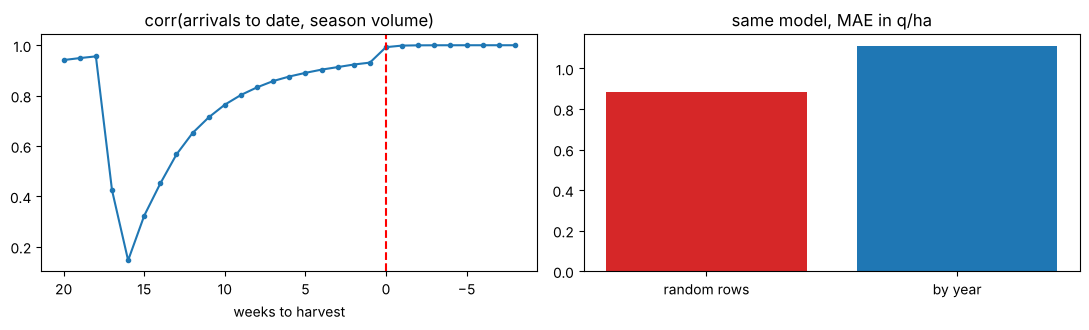

In [7]:
# mandi arrivals to date vs final season volume, by weeks to harvest (0 = harvest week)
d = df[df.season_year >= 2011].copy()
d['arr'] = d.groupby(key).mandi_arrivals_qtl.cumsum()
d['volume'] = d.yield_q_ha * d.area_ha
prof = pd.Series({wk: d[d.weeks_to_harvest == wk].arr.corr(d[d.weeks_to_harvest == wk].volume) for wk in range(-8, 21)})

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(prof.index, prof.values, marker='o', ms=3)
ax[0].axvline(0, color='red', ls='--')
ax[0].invert_xaxis()
ax[0].set_xlabel('weeks to harvest')
ax[0].set_title('corr(arrivals to date, season volume)')

# same model, random row split vs split by year
from sklearn.ensemble import HistGradientBoostingRegressor as HGB
cat_idx = [FEATS.index('crop_code'), FEATS.index('district_code')]

def quick_model():
    return HGB(loss='absolute_error', max_iter=120, learning_rate=0.1, max_depth=6, categorical_features=cat_idx, random_state=0)

old = M[M.season_year <= 2021]
rs = np.random.RandomState(0)
pick = rs.rand(len(old)) < 0.8
m1 = quick_model().fit(old[pick][FEATS], old[pick].y_ratio, sample_weight=old[pick].baseline)
t1 = old[~pick & old.lead6]
mae_random = (np.abs(m1.predict(t1[FEATS]) - t1.y_ratio) * t1.baseline).mean()

tr = M[M.season_year <= 2020]
va = M[(M.season_year == 2021) & M.lead6]
m2 = quick_model().fit(tr[FEATS], tr.y_ratio, sample_weight=tr.baseline)
mae_year = (np.abs(m2.predict(va[FEATS]) - va.y_ratio) * va.baseline).mean()
print('MAE random row split: %.3f q/ha | split by year: %.3f q/ha' % (mae_random, mae_year))
ax[1].bar(['random rows', 'by year'], [mae_random, mae_year], color=['tab:red', 'tab:blue'])
ax[1].set_title('same model, MAE in q/ha')
plt.tight_layout()
plt.savefig('../reports/figures/04_leakage.png', dpi=120)

# lag1 must be the actual yield of the previous season
prev = S[['taluka', 'crop', 'season_year', 'yield_q_ha']].copy()
prev['season_year'] += 1
chk = M.drop_duplicates(key).merge(prev.rename(columns={'yield_q_ha': 'prev'}), on=key, how='left')
print('lag1 check, max difference:', (chk.yield_lag1 - chk.prev).abs().max())

## Leakage findings

- `season_mandi_arrivals_qpha` (season total arrivals per ha) is almost a copy of the target. Dropped.
- Weekly arrivals only tell us about the season after harvest starts (left plot). I do not use them, and I stop forecast origins 4 weeks before harvest.
- A random row split gives a better-looking MAE than a split by year, because weeks of the same season end up on both sides. Everything below is split by year.
- Normal rainfall, soil medians and the rain fill use only years up to 2021.

## Split

- Train: 2011-2021
- Validation: 2022-2023
- Test: 2024-2025 (not touched until the end)
- Cross-validation: expanding window, validate on 2019, 2020, 2021, each trained on all earlier years

In [8]:
M['period'] = np.where(M.season_year <= 2021, 'train', np.where(M.season_year <= 2023, 'valid', 'test'))
print(M.groupby('period').size().rename('rows'))
print(M[M.lead6].groupby('period').size().rename('rows at 6 weeks before harvest'))

keep = key + ['district', 'season_week', 'yield_q_ha', 'area_ha', 'baseline', 'y_ratio', 'lead6', 'period', 'price_q'] + FEATS
M[keep].to_csv('../dataset/model_data.csv', index=False)
json.dump(FEATS, open('../dataset/feature_list.json', 'w'))
print('saved', M[keep].shape)

period
test     14784
train    81312
valid    14784
Name: rows, dtype: int64
period
test      840
train    4620
valid     840
Name: rows at 6 weeks before harvest, dtype: int64
saved (110880, 37)
